# Why conditions 02 and 03 are unstable, and how to fix them

Diagnosis of the wider-prior NPE fits `02AElatentAM_wider` and `03EnvLatentAM_wider`, run on 2026-11-08. Every experiment is in this folder (`run_rc_paper_wider/diagnose_02_03`). No production script or engine file was changed.

The local simulations use small populations (N = 6,000 to 12,000, against 40,000 in production). Use the numbers here to decide what to change. They are not final estimates.

> **Update, later on 2026-11-08.** The engine has since been changed so that `d_mat` and `a_mat` scale the effects and `s_mat` is applied, and `Scripts/run_rc_paper_rescaled/` holds the generators for the re-run. Condition 03 keeps `re` and `prop_h2_latent1` fixed, now at 0.7 and 0.7, rather than freeing them as section 7.2 suggests, and `s` is applied at 0.3 rather than dropped. Those values come from `choose_03_fixed_values.py` and `verify_03_fixed_values.py` (`results/exp6_*`; the `_s3` files are for `s` = 0.3). The "production scale" runs below used the engine as it was before the change, so they can no longer be regenerated with it.

## Conclusions

**1. `vg1` does not set EA's base genetic variance in the simulations, which is why its estimates sit at the lower edge.** The engine scales each trait's effect sizes so that its genetic variance is about 1, whatever `vg1` is. `a_mat` and `d_mat` only decide which variants count as observed. So `vg1` only sets the environmental variance, `1 - vg1`, and heritability in the founders (generation 0) is `1 / (2 - vg1)`. That can never be below 0.51. A fitted `vg1` of 0.06 means a founder heritability of 0.52, the lowest the training data offer. This applies to every condition, including condition 04, where the fitted 0.28 means 0.58.

**2. At that floor, the model cannot produce the spouse and sibling correlations together.** None of the 40,000 training rows for 02 and 03 reaches the observed spouse phenotypic, spouse PGS and sibling phenotypic correlations at the same time. Rows that reach the two spouse correlations have a sibling phenotypic correlation of at least 0.40 in 02 and at least 0.60 in 03, against 0.37 observed. The fit responds by pushing `vg1` as low as the range allows.

**3. Condition 03 has a second problem: `re` is fixed at 0.1.** The genetic correlation is then almost the only link between EA and the mating trait. Once the scale is corrected, the best fit reaches a spouse phenotypic correlation of only 0.25 (observed 0.43), whether `vg1` is restricted or free. The fixed `s = 0.5` has no effect at all, because the engine never applies `s_mat`.

**4. Changing the range of `vg1` or adding observation noise does not fix it.** Restricting the training data to `vg1` between 0.25 and 0.45 moves condition 02's estimate to the new lower edge (0.27). Adding observation noise to the training data leaves it at the old edge (0.055). In condition 03, none of the posterior falls inside the simulated range in any of the four fits. The fits report far more certainty than the data allow: 02 gives `vg1` = 0.057 ± 0.006, while the 200 closest simulated rows run from 0.07 to 0.54.

**5. With the scale corrected, `vg1` around 0.3 to 0.4 is supported.** In condition 02, the fit is best for `vg1` between about 0.27 and 0.50, with no restriction imposed. In condition 03 the data do not determine `vg1` (the fit is flat from 0.05 to 0.6), so 0.3 to 0.4 can be imposed at no cost in fit.

**6. The corrected designs reproduce the observed correlations much better**, verified with replicated simulations (section 6). *Misfit* is the root mean square, over the 52 correlations, of (simulated - observed) / sqrt(SE² + 0.01²).

| Model | Misfit | Sibling phenotypic r (observed 0.369) | Spouse phenotypic r (observed 0.433) |
|---|---|---|---|
| 02, current estimates | 2.68 | 0.436 | 0.441 |
| 02, corrected scale, `vg1` 0.3 to 0.4 | 1.96 | 0.359 | 0.424 |
| 02, also with family environment | 1.61 | 0.387 | 0.405 |
| 03, current estimates | 8.44 | 0.638 | 0.452 |
| 03, corrected scale only (`re` still 0.1) | 4.10 | 0.373 | 0.250 |
| 03, corrected scale, `re` and `prop_h2_latent1` free | 2.06 | 0.384 | 0.449 |
| 03, also with family environment | 1.54 | 0.361 | 0.383 |

**What to change** (details and code in section 7):

1. Multiply the effect sizes by `sqrt(vg)` so `vg1` really is the base genetic variance. This is a small change to the generators and predicted-condition scripts, with no engine change.
2. In condition 03, free `re` and `prop_h2_latent1`, and drop the `s` values.
3. Narrow the sampling ranges to where the observed pattern can occur.
4. Decide whether to add a family-environment term. It gives the largest further gain, but condition 02 would no longer be a pure AE model.

Then regenerate the training data, refit, and re-simulate. No NPE has been trained on corrected-scale data yet, so the improvement in NPE stability is expected but not shown here.

In [1]:
import json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from common import NPE, RESULTS, load_observed, load_training, misfit
from summarize_npe import load_all

BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8983"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#bdbcb6", "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e8e7e3", "grid.linewidth": 0.8, "axes.axisbelow": True, "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left", "legend.frameon": False,
    "xtick.color": "#52514e", "ytick.color": "#52514e", "axes.labelcolor": "#52514e", "lines.linewidth": 2,
})
pd.set_option("display.max_columns", 40, "display.width", 200)
FIT = {"02": "02AElatentAM_wider", "03": "03EnvLatentAM_wider"}
train = {k: load_training(v) for k, v in FIT.items()}
F = train["02"][1]
obs, se = train["02"][3], train["02"][4]
OBS = pd.Series(obs, index=F)

## 1. What `vg1` actually does

Each run below uses random mating and no vertical transmission, so founder values can be read directly. Two versions are compared at each `vg1` setting (three replicates each):

- **Production scale**: the generators as they run today.
- **True scale**: effect sizes multiplied by `sqrt(vg)`, passed to the unmodified engine through its `cv_info` argument. The genetic variance then equals `vg`.

Genetic variance  Environmental variance  Phenotypic variance  Founder heritability  Sibling phenotypic r
                 vg1 setting                                                                                                           
Production scale 0.05                    0.979                   0.947                1.917                 0.511                 0.247
                 0.10                    1.025                   0.900                1.919                 0.534                 0.270
                 0.20                    1.015                   0.802                1.812                 0.560                 0.276
                 0.35                    1.031                   0.646                1.687                 0.611                 0.297
                 0.50                    0.982                   0.499                1.477                 0.664                 0.333
                 0.80                    1.053                   0.199                1.254                 0.840                 0.426
                 0.95                    1.011                   0.049                1.061                 0.953                 0.474
True scale       0.05                    0.049                   0.947                0.994                 0.049                 0.023
                 0.10                    0.102                   0.900                1.000                 0.102                 0.048
                 0.20                    0.203                   0.802                1.003                 0.202                 0.110
                 0.35                    0.361                   0.646                1.013                 0.356                 0.170
                 0.50                    0.491                   0.499                0.987                 0.497                 0.251
                 0.80                    0.843                   0.199                1.043                 0.808                 0.405
                 0.95                    0.961                   0.049                1.010                 0.951                 0.470

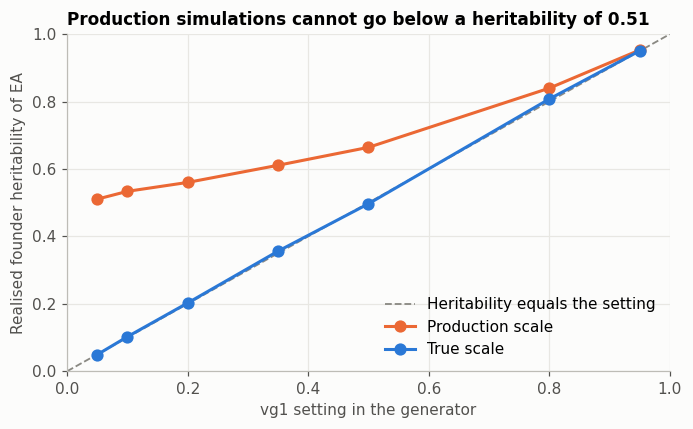

In [2]:
e1 = pd.read_csv(RESULTS / "exp1_engine_scale.csv")
e1["scale"] = e1["scale"].map({"engine": "Production scale", "true": "True scale"})
tab = e1.groupby(["scale", "param_vg1"])[["VG1_gen0", "VE1_gen0", "VP1_gen0", "h2_1_gen0", "S_Y1"]].mean()
tab.index.names = ["", "vg1 setting"]
tab.columns = ["Genetic variance", "Environmental variance", "Phenotypic variance", "Founder heritability", "Sibling phenotypic r"]
display(tab.round(3))

m = e1.groupby(["scale", "param_vg1"])["h2_1_gen0"].mean().unstack(0)
fig, ax = plt.subplots(figsize=(6.4, 4))
ax.plot([0, 1], [0, 1], ls="--", color=GREY, lw=1.2, label="Heritability equals the setting")
ax.plot(m.index, m["Production scale"], "-o", color=ORANGE, ms=7, label="Production scale")
ax.plot(m.index, m["True scale"], "-o", color=BLUE, ms=7, label="True scale")
ax.set(xlabel="vg1 setting in the generator", ylabel="Realised founder heritability of EA", xlim=(0, 1), ylim=(0, 1))
ax.set_title("Production simulations cannot go below a heritability of 0.51")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

The genetic variance is about 1.0 at every `vg1` setting under the production scale, and the heritability runs from 0.51 to 0.95 instead of 0.05 to 0.95. Trait 2 is affected the same way: `vg2 = 0.5` gives a heritability of 0.67, not 0.5.

The engine's own README says generation-0 variances are "set by the matrices supplied to the constructor", so the code and its documentation disagree. The training rows already generated remain valid simulations; only the meaning of their `vg1` and `vg2` labels is different from what was intended.

## 2. The observed correlations are in range one at a time, but not together

Every one of the 52 observed correlations falls inside the range of the training rows. The problem appears only when correlations are considered jointly, as the next figure and table show.

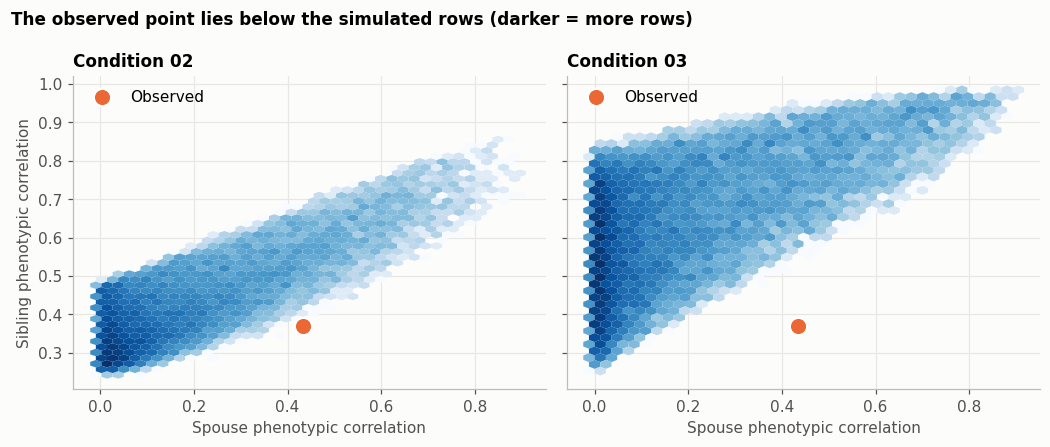

Condition,02,03
Training rows,20000.000,20000.000
Spouse phenotypic r in 0.41-0.46,618.000,625.000
...and spouse PGS r in 0.13-0.19,82.000,267.000
...and sibling phenotypic r in 0.34-0.40,0.000,0.000
Lowest sibling phenotypic r among the spouse-matching rows,0.402,0.604


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(9.6, 4.1), sharex=True, sharey=True)
for ax, (k, title) in zip(axes, [("02", "Condition 02"), ("03", "Condition 03")]):
    df = train[k][0]
    ax.hexbin(df["M_Y1"], df["S_Y1"], gridsize=38, cmap="Blues", mincnt=1, bins="log", linewidths=0)
    ax.scatter(OBS["M_Y1"], OBS["S_Y1"], s=130, color=ORANGE, edgecolor="white", linewidth=1.5, zorder=5, label="Observed")
    ax.set_title(title); ax.set_xlabel("Spouse phenotypic correlation"); ax.legend(loc="upper left")
axes[0].set_ylabel("Sibling phenotypic correlation")
fig.suptitle("The observed point lies below the simulated rows (darker = more rows)", x=0.01, ha="left", fontweight="bold", fontsize=11)
plt.tight_layout(); plt.show()

rows = []
for k in FIT:
    df = train[k][0]
    a = df["M_Y1"].between(.41, .46); b = df["M_PGS1"].between(.13, .19); c = df["S_Y1"].between(.34, .40)
    rows.append({"Condition": k, "Training rows": len(df), "Spouse phenotypic r in 0.41-0.46": int(a.sum()),
                 "...and spouse PGS r in 0.13-0.19": int((a & b).sum()),
                 "...and sibling phenotypic r in 0.34-0.40": int((a & b & c).sum()),
                 "Lowest sibling phenotypic r among the spouse-matching rows": round(df.loc[a & b, "S_Y1"].min(), 3)})
display(pd.DataFrame(rows).set_index("Condition").T)

No training row in either condition matches the three correlations together. To reach a spouse correlation of 0.43, the production-scale model needs strong assortment, and with heritability above 0.51 that makes siblings too similar. The fit moves `vg1` down to reduce heritability as far as it can, then runs out of range.

## 3. What restricting each parameter does to the fit

For the existing training data, this section splits each parameter's range into six equal bins and takes the mean misfit of the 20 closest rows in each bin. Low values mean the data can be matched there. A flat line means the observed correlations say little about that parameter.

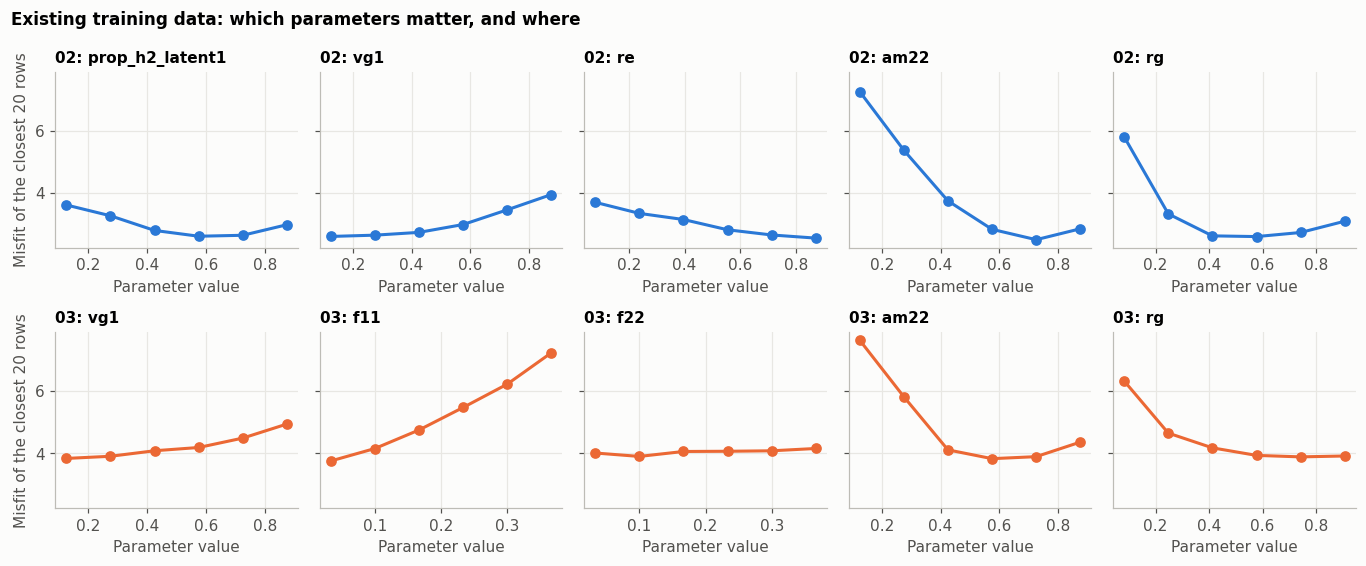

In [4]:
def best_by_bin(k, n_bins=6, top=20):
    df, feats, pars, o, s = train[k]
    m = misfit(df[feats].to_numpy(float), o, s)
    out = {}
    for p in pars:
        v = df[f"param_{p}"].to_numpy()
        edges = np.linspace(v.min(), v.max(), n_bins + 1)
        out[p] = ((edges[:-1] + edges[1:]) / 2,
                  [np.sort(m[(v >= a) & (v <= b)])[:top].mean() for a, b in zip(edges[:-1], edges[1:])])
    return out

fig, axes = plt.subplots(2, 5, figsize=(12.5, 5.2), sharey=True)
for row, (k, color) in enumerate([("02", BLUE), ("03", ORANGE)]):
    for ax, (p, (x, y)) in zip(axes[row], best_by_bin(k).items()):
        ax.plot(x, y, "-o", color=color, ms=6)
        ax.set_title(f"{k}: {p}", fontsize=10); ax.set_xlabel("Parameter value")
    axes[row, 0].set_ylabel("Misfit of the closest 20 rows")
fig.suptitle("Existing training data: which parameters matter, and where", x=0.01, ha="left", fontweight="bold", fontsize=11)
plt.tight_layout(); plt.show()

- Assortment and the genetic correlation matter most: low `am22` or low `rg` cannot produce the spouse correlations.
- Condition 02 is about equally good for `vg1` from 0.05 to 0.5 on the production scale, so that range was never strongly preferred. Its fitted 0.057 ± 0.006 reflects the fit's behaviour rather than a real preference in the data.
- Condition 03 fits better as `f11` falls, and its best attainable misfit (about 3.6) is well above condition 02's (about 2.3), even though it has as many free parameters. `f22` is flat, and the fit recovers it poorly (test R² 0.57).

## 4. Why the fits are unstable

These checks explain why the NPE estimates move so much between fits.

In [5]:
# ---- Closest simulated rows against the NPE posterior
rows = []
for k, fit in FIT.items():
    df, feats, pars, o, s = train[k]
    m = misfit(df[feats].to_numpy(float), o, s)
    near = df.iloc[np.argsort(m)[:200]]
    post = pd.read_csv(NPE / f"results_npe_unweighted_{fit}" / "predictions" / "posterior_summary.csv").set_index("parameter")
    for p in pars:
        rows.append({"Condition": k, "Parameter": p,
                     "200 closest rows, 5th percentile": near[f"param_{p}"].quantile(.05),
                     "200 closest rows, median": near[f"param_{p}"].median(),
                     "200 closest rows, 95th percentile": near[f"param_{p}"].quantile(.95),
                     "NPE mean": post.loc[p, "mean"], "NPE SD": post.loc[p, "std"]})
display(pd.DataFrame(rows).set_index(["Condition", "Parameter"]).round(3))

# ---- Refits on the existing data
d = load_all()
d["estimate"] = d["mean"].map("{:.3f}".format) + " ± " + d["sd"].map("{:.3f}".format)
d["variant"] = d["variant"].map({"production": "Production fit", "vgwin": "vg1 restricted to 0.25-0.45",
                                 "noise": "Observation noise added", "both": "Restricted + noise"})
order = ["Production fit", "vg1 restricted to 0.25-0.45", "Observation noise added", "Restricted + noise"]
wide = d.pivot_table(index=["condition", "parameter"], columns="variant", values="estimate", aggfunc="first")
display(wide[[c for c in order if c in wide.columns]])
share = d.groupby(["condition", "variant"])["inside"].first().unstack(1).round(4)
share.index.name = "Share of the unrestricted posterior inside the simulated range"
display(share[[c for c in order if c in share.columns]])

200 closest rows, 5th percentile  200 closest rows, median  200 closest rows, 95th percentile  NPE mean  NPE SD
Condition Parameter                                                                                                                       
02        prop_h2_latent1                             0.366                     0.642                              0.838     0.674   0.039
          vg1                                         0.068                     0.278                              0.543     0.057   0.006
          re                                          0.447                     0.770                              0.935     0.806   0.028
          am22                                        0.566                     0.709                              0.867     0.726   0.009
          rg                                          0.392                     0.577                              0.855     0.673   0.021
03        vg1                                         0.070                     0.271                              0.615     0.092   0.050
          f11                                         0.003                     0.035                              0.097     0.092   0.020
          f22                                         0.015                     0.173                              0.372     0.112   0.072
          am22                                        0.472                     0.618                              0.814     0.694   0.055
          rg                                          0.380                     0.665                              0.962     0.917   0.203

variant                       Production fit vg1 restricted to 0.25-0.45 Observation noise added Restricted + noise
condition     parameter                                                                                            
02AElatentAM  am22             0.726 ± 0.009               0.734 ± 0.008           0.736 ± 0.009      0.758 ± 0.009
              prop_h2_latent1  0.674 ± 0.039               0.621 ± 0.058           0.651 ± 0.052      0.599 ± 0.068
              re               0.806 ± 0.028               0.924 ± 0.021           0.875 ± 0.037      0.940 ± 0.013
              rg               0.673 ± 0.021               0.604 ± 0.019           0.637 ± 0.021      0.570 ± 0.023
              vg1              0.057 ± 0.006               0.269 ± 0.033           0.055 ± 0.005      0.255 ± 0.006
03EnvLatentAM am22             0.694 ± 0.055               0.596 ± 0.036           0.770 ± 0.013      0.733 ± 0.016
              f11              0.092 ± 0.020               0.070 ± 0.079           0.299 ± 0.123      0.067 ± 0.050
              f22              0.112 ± 0.072               0.260 ± 0.083           0.001 ± 0.001      0.012 ± 0.013
              rg               0.917 ± 0.203               0.853 ± 0.046           0.749 ± 0.056      0.760 ± 0.043
              vg1              0.092 ± 0.050               0.320 ± 0.050           0.109 ± 0.067      0.357 ± 0.059

variant,Production fit,vg1 restricted to 0.25-0.45,Observation noise added,Restricted + noise
Share of the unrestricted posterior inside the simulated range,,,,
02AElatentAM,0.072,0.0,0.0104,0.0455
03EnvLatentAM,0.000,0.0,0.0000,0.0000


In [6]:
# ---- How much of the Mahalanobis distance is observation noise?
rows = []
rng = np.random.default_rng(1)
for k in FIT:
    df, feats, _, o, s = train[k]
    X = df[feats].to_numpy(float)
    mu, inv = X.mean(0), np.linalg.pinv(np.cov(X, rowvar=False))
    dist = lambda a: np.sqrt(np.einsum("...i,ij,...j", a - mu, inv, a - mu))
    clean, noisy = dist(X), dist(X + rng.normal(0, s, size=X.shape))
    rows.append({"Condition": k, "Observed": dist(o), "Training rows, median": np.median(clean), "Training rows, max": clean.max(),
                 "Rows with observed-sized noise, median": np.median(noisy), "Rows with observed-sized noise, max": noisy.max()})
display(pd.DataFrame(rows).set_index("Condition").round(1))

# ---- The second mode at rg near 0 in condition 03
df, feats, _, o, s = train["03"]
m = misfit(df[feats].to_numpy(float), o, s)
bins = [(0, .1), (.1, .3), (.3, .6), (.6, .8), (.8, .99)]
display(pd.DataFrame([{"rg range": f"{a}-{b}", "Highest spouse phenotypic r simulated": df.loc[df.param_rg.between(a, b), "M_Y1"].max(),
                       "Lowest misfit": m[df.param_rg.between(a, b).to_numpy()].min()} for a, b in bins]).set_index("rg range").round(3))

,Observed,"Training rows, median","Training rows, max","Rows with observed-sized noise, median","Rows with observed-sized noise, max"
Condition,,,,,
02,54.4,7.0,16.5,32.4,59.5
03,50.4,7.1,15.8,30.5,58.6


,Highest spouse phenotypic r simulated,Lowest misfit
rg range,,
0-0.1,0.120,7.294
0.1-0.3,0.483,4.258
0.3-0.6,0.792,3.610
0.6-0.8,0.873,3.646
0.8-0.99,0.905,3.602


**The fits are outside what the training data can support.** NPE gives very narrow intervals (02: `vg1` ± 0.006), while the closest simulated rows spread over most of the range. The flow is extrapolating to an input it was not trained on. Condition 03's posterior has none of its mass inside the simulated range, and its estimates swing widely as a result: 0.73 under the narrow prior, 0.60 for the unrestricted flow and 0.09 after restriction.

**Restricting the range moves the problem without solving it.** Condition 02's `vg1` follows the window down to its lower edge (0.27, or 0.255 with noise as well). Condition 03's lands inside its window (0.32), but only because `vg1` is not determined there, and none of its posterior falls inside the range in any of the four fits.

**Observation noise is not the fix either.** Adding it left condition 02's `vg1` at the edge, with almost the same posterior width. In condition 03 it moved `f11` from 0.09 to 0.30 and `f22` from 0.11 to 0.00. Estimates that shift this much after a small change to the training data are not determined by the data.

**A correction to the earlier summary of these fits.** The earlier report treated the distance of 41 to 54 between the observed correlations and the training rows as evidence of misfit. Most of that distance is noise: training rows given observed-sized noise have a median of about 30 and a maximum near 59. The misfit evidence that holds up is the joint comparison in section 2.

**The `rg` near 0 mode in condition 03 is an artefact.** Rows with `rg` below 0.1 never exceed a spouse phenotypic correlation of 0.12, so that mode cannot be a real solution.

## 5. Local simulations with the scale corrected

Each design below was simulated 140 times (Latin hypercube over the free parameters, N = 6,000, 500 variants, 15 generations, real engine). Gaussian-process emulators of the 52 correlations then gave each design's best parameters and the profile curves in this section. The best parameters were re-simulated in section 6.

In [7]:
from run_design import DESIGNS
LABEL = {
    "02_current": "02: current estimates, production scale",
    "02_base": "02: true scale, vg1 0.3-0.4",
    "02_freevg": "02: true scale, vg1 free",
    "02_vg2": "02: true scale, vg1 0.3-0.4, vg2 free",
    "02_c": "02: true scale, vg1 0.3-0.4, vg2 free, family environment",
    "03_current": "03: current estimates, production scale",
    "03_base": "03: true scale, vg1 0.3-0.4, re = 0.1",
    "03_freevg": "03: true scale, vg1 free, re = 0.1",
    "03_re": "03: true scale, vg1 0.3-0.4, re and prop_h2_latent1 free",
    "03_re_freevg": "03: true scale, vg1 free, re and prop_h2_latent1 free",
    "03_re_vg2": "03: as 03_re, vg2 also free",
    "03_re_c": "03: as 03_re, with family environment",
}
fmt = lambda d: ", ".join(f"{k} {v[0]:g}-{v[1]:g}" for k, v in d.items())
display(pd.DataFrame([{"Design": k, "Description": LABEL[k], "Free parameters and ranges": fmt(v["free"]),
                       "Fixed": ", ".join(f"{a} = {b}" for a, b in v["fixed"].items()) or "-"} for k, v in DESIGNS.items()]).set_index("Design").style.set_properties(**{"text-align": "left"}))

,Description,Free parameters and ranges,Fixed
Design,,,
02_base,"02: true scale, vg1 0.3-0.4","vg1 0.3-0.4, prop_h2_latent1 0.05-0.95, re 0-0.95, am22 0.05-0.95, rg 0-0.99",vg2 = 0.5
02_freevg,"02: true scale, vg1 free","vg1 0.05-0.95, prop_h2_latent1 0.05-0.95, re 0-0.95, am22 0.05-0.95, rg 0-0.99",vg2 = 0.5
02_vg2,"02: true scale, vg1 0.3-0.4, vg2 free","vg1 0.3-0.4, vg2 0.1-0.95, prop_h2_latent1 0.05-0.95, re 0-0.95, am22 0.05-0.95, rg 0-0.99",-
02_c,"02: true scale, vg1 0.3-0.4, vg2 free, family environment","vg1 0.3-0.4, vg2 0.1-0.6, c1 0-0.35, c2 0-0.35, prop_h2_latent1 0.05-0.95, re 0-0.95, am22 0.05-0.95, rg 0-0.99",-
03_base,"03: true scale, vg1 0.3-0.4, re = 0.1","vg1 0.3-0.4, f11 0-0.4, f22 0-0.4, am22 0.05-0.95, rg 0-0.99","vg2 = 0.5, re = 0.1, prop_h2_latent1 = 0.7"
03_freevg,"03: true scale, vg1 free, re = 0.1","vg1 0.05-0.95, f11 0-0.4, f22 0-0.4, am22 0.05-0.95, rg 0-0.99","vg2 = 0.5, re = 0.1, prop_h2_latent1 = 0.7"
03_re,"03: true scale, vg1 0.3-0.4, re and prop_h2_latent1 free","vg1 0.3-0.4, f11 0-0.4, f22 0-0.4, re 0-0.95, prop_h2_latent1 0.05-0.95, am22 0.05-0.95, rg 0-0.99",vg2 = 0.5
03_re_freevg,"03: true scale, vg1 free, re and prop_h2_latent1 free","vg1 0.05-0.95, f11 0-0.4, f22 0-0.4, re 0-0.95, prop_h2_latent1 0.05-0.95, am22 0.05-0.95, rg 0-0.99",vg2 = 0.5
03_re_c,"03: as 03_re, with family environment","vg1 0.3-0.4, f11 0-0.4, f22 0-0.4, c1 0-0.35, c2 0-0.35, re 0-0.95, prop_h2_latent1 0.05-0.95, am22 0.05-0.95, rg 0-0.99",vg2 = 0.5


`c1` and `c2` are a shared family environment: one draw per sibship, added to EA and to the mating trait and perfectly correlated between them. The engine has no such term, so it is added through the engine's existing `_post_offspring_hook` (`FamilyEnvSimulation` in `sim_driver.py`).

The profile curves below hold one parameter at each value of a grid and let the others adjust. A flat curve means the observed correlations do not determine that parameter.

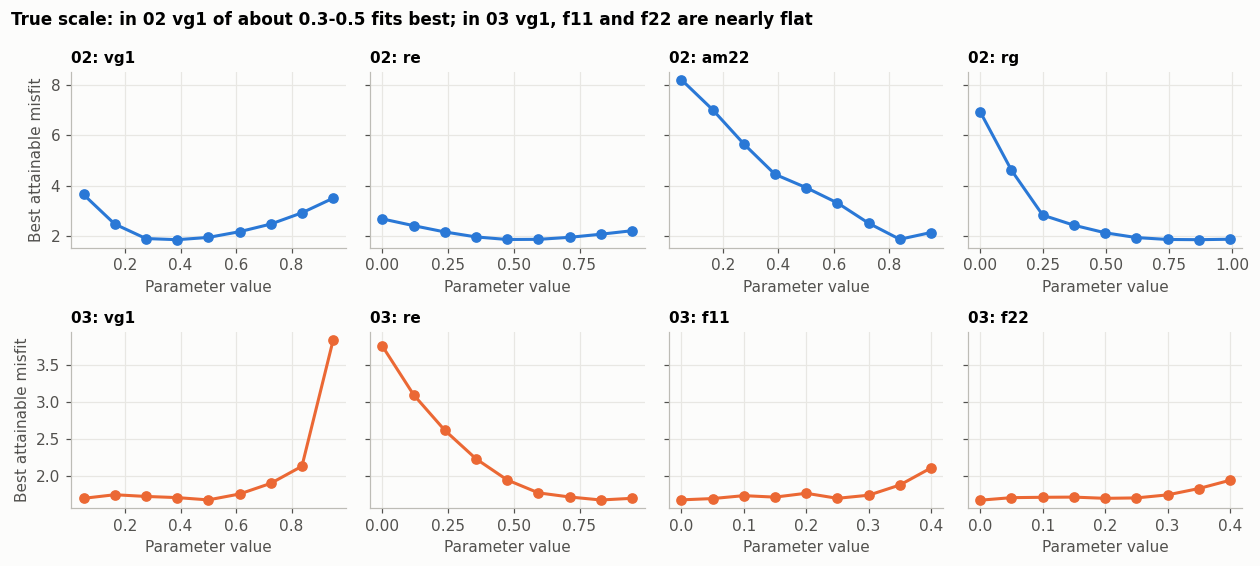

5th to 95th percentile of the parameter values fitting within 15% of the best misfit,02_base,02_c,03_re,03_re_c
parameter,,,,
am22,0.77 to 0.93,0.66 to 0.90,0.59 to 0.82,0.67 to 0.83
c1,-,0.06 to 0.20,-,0.01 to 0.22
c2,-,0.10 to 0.32,-,0.03 to 0.33
f11,-,-,0.01 to 0.15,0.01 to 0.14
f22,-,-,0.02 to 0.22,0.04 to 0.21
prop_h2_latent1,0.64 to 0.84,0.51 to 0.85,0.53 to 0.84,0.51 to 0.81
re,0.31 to 0.64,0.33 to 0.86,0.46 to 0.91,0.35 to 0.87
rg,0.61 to 0.91,0.51 to 0.90,0.51 to 0.94,0.51 to 0.78
vg1,0.31 to 0.40,0.30 to 0.38,0.31 to 0.40,0.31 to 0.38


In [8]:
p = pd.read_csv(RESULTS / "exp4_profiles.csv")
panels = [("02_freevg", ["vg1", "re", "am22", "rg"], BLUE, "02"), ("03_re_freevg", ["vg1", "re", "f11", "f22"], ORANGE, "03")]
fig, axes = plt.subplots(2, 4, figsize=(11.5, 5.2), sharey="row")
for row, (design, pars, color, name) in enumerate(panels):
    for ax, par in zip(axes[row], pars):
        g = p[(p.design == design) & (p.parameter == par)]
        ax.plot(g.value, g.misfit, "-o", color=color, ms=6)
        ax.set_title(f"{name}: {par}", fontsize=10); ax.set_xlabel("Parameter value")
    axes[row, 0].set_ylabel("Best attainable misfit")
fig.suptitle("True scale: in 02 vg1 of about 0.3-0.5 fits best; in 03 vg1, f11 and f22 are nearly flat", x=0.01, ha="left", fontweight="bold", fontsize=11)
plt.tight_layout(); plt.show()

r = pd.read_csv(RESULTS / "exp4_good_region.csv")
r["range"] = r.apply(lambda a: f"{a.q05:.2f} to {a.q95:.2f}", axis=1)
wide = r.pivot(index="parameter", columns="design", values="range").reindex(columns=["02_base", "02_c", "03_re", "03_re_c"]).fillna("-")
wide.columns.name = "5th to 95th percentile of the parameter values fitting within 15% of the best misfit"
display(wide)

- **Condition 02 identifies `vg1`.** Misfit is lowest for values of about 0.27 to 0.50, and much higher at 0.05 (3.66) and at 0.95 (3.51). The 0.3 to 0.4 you were aiming for sits inside that interval without being imposed.
- **Condition 03 does not identify `vg1`.** Misfit is flat from 0.05 to 0.6, as it is for `f11` and `f22` over most of their range. Family resemblance can come from several sources here, so vertical transmission and heritability trade off. If `f11` is large the fit gets worse, not better.
- **`re` in condition 03 has to be well above 0.1.** At `re` of 0 to 0.12 the misfit is 3.1 to 3.8. The fit is best from about 0.6 to 0.95, so the EA environment and the mating trait's environment have to be strongly correlated.

Differences in misfit below about 0.3 are within the emulators' accuracy (cross-validated error of about 0.02 to 0.03 on the correlation scale).

## 6. Verification with replicated simulations

The best parameters of each design were re-simulated at N = 12,000 (500 variants, 15 generations, 6 replicates), next to the current production estimates at the same size and seeds. The misfit below is that of the correlations averaged over the 6 replicates. The bars show a 90% bootstrap interval over replicates.

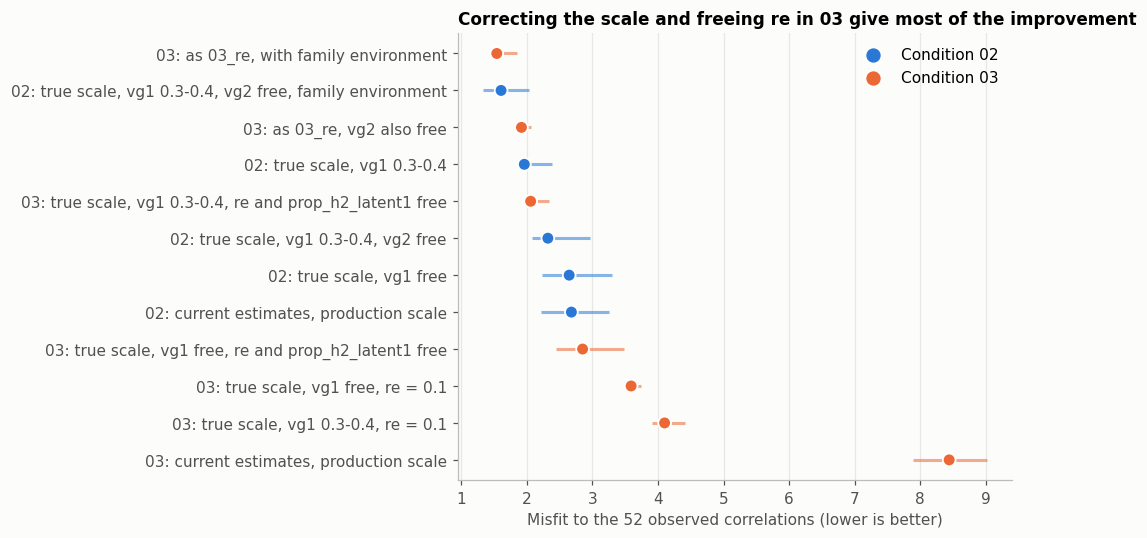

design,Observed,02_current,02_base,02_c,03_current,03_base,03_re,03_re_c
S_PGS1,0.562,0.590,0.572,0.557,0.629,0.590,0.551,0.559
M_PGS1,0.158,0.176,0.153,0.120,0.271,0.200,0.115,0.126
MS_PGS1,0.117,0.139,0.117,0.085,0.224,0.179,0.092,0.096
S_Y1,0.369,0.436,0.359,0.387,0.638,0.373,0.384,0.361
SC_Y1,0.202,0.312,0.263,0.213,0.504,0.291,0.264,0.196
PSC_Y1,0.160,0.232,0.197,0.133,0.406,0.222,0.192,0.129
M_Y1,0.433,0.441,0.424,0.405,0.452,0.250,0.449,0.383
MS_Y1,0.261,0.264,0.238,0.241,0.378,0.210,0.235,0.245
SMS_Y1,0.171,0.150,0.136,0.146,0.314,0.180,0.119,0.151
MSM_Y1,0.200,0.212,0.204,0.202,0.235,0.134,0.203,0.217


,Founder VG,Founder h2,Final VG,Final h2,Final PGS R2,Final VF,"Final r(EA, mating trait)",Final phenotypic variance of the mating trait
design,,,,,,,,
02_current,1.009,0.513,1.631,0.632,0.154,0.000,0.785,2.958
02_base,0.395,0.391,0.661,0.521,0.100,0.000,0.704,1.721
02_c,0.389,0.430,0.533,0.460,0.133,0.000,0.748,1.461
03_current,1.007,0.523,2.208,0.556,0.104,0.095,0.810,4.267
03_base,0.386,0.383,0.688,0.531,0.111,0.000,0.646,6.757
03_re,0.394,0.390,0.563,0.428,0.101,0.018,0.813,2.249
03_re_c,0.304,0.343,0.437,0.384,0.093,0.000,0.729,2.015


In [9]:
v = pd.DataFrame([json.loads(l) for l in open(RESULTS / "exp5_verify.jsonl")])
if "error" in v: v = v[v["error"].isna()]
rng = np.random.default_rng(1)
rows = []
for design, g in v.groupby("design"):
    X = g[F].to_numpy(float)
    boot = [misfit(X[rng.integers(0, len(X), len(X))].mean(0), obs, se) for _ in range(2000)]
    rows.append(dict(design=design, n=len(g), misfit=misfit(X.mean(0), obs, se), low=np.percentile(boot, 5), high=np.percentile(boot, 95)))
res = pd.DataFrame(rows).sort_values("misfit", ascending=False).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(9.4, 5))
colors = [BLUE if d.startswith("02") else ORANGE for d in res.design]
ax.hlines(res.index, res.low, res.high, color=colors, lw=2, alpha=.55)
ax.scatter(res.misfit, res.index, c=colors, s=70, edgecolor="white", linewidth=1.2, zorder=3)
ax.set_yticks(res.index); ax.set_yticklabels([LABEL[d] for d in res.design])
ax.set_xlabel("Misfit to the 52 observed correlations (lower is better)")
ax.set_title("Correcting the scale and freeing re in 03 give most of the improvement")
ax.scatter([], [], c=BLUE, s=70, label="Condition 02"); ax.scatter([], [], c=ORANGE, s=70, label="Condition 03"); ax.legend(loc="upper right")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

key = ["S_PGS1", "M_PGS1", "MS_PGS1", "S_Y1", "SC_Y1", "PSC_Y1", "M_Y1", "MS_Y1", "SMS_Y1", "MSM_Y1"]
show = ["02_current", "02_base", "02_c", "03_current", "03_base", "03_re", "03_re_c"]
mean = v.groupby("design")[key].mean().loc[show].T
mean.insert(0, "Observed", OBS[key])
display(mean.round(3))

vc = v.groupby("design")[["VG1_gen0", "h2_1_gen0", "VG1_final", "h2_1_final", "h2obs_1_final", "VF1_final", "r_Y1Y2_final", "VP2_final"]].mean().loc[show]
vc.columns = ["Founder VG", "Founder h2", "Final VG", "Final h2", "Final PGS R2", "Final VF", "Final r(EA, mating trait)", "Final phenotypic variance of the mating trait"]
display(vc.round(3))

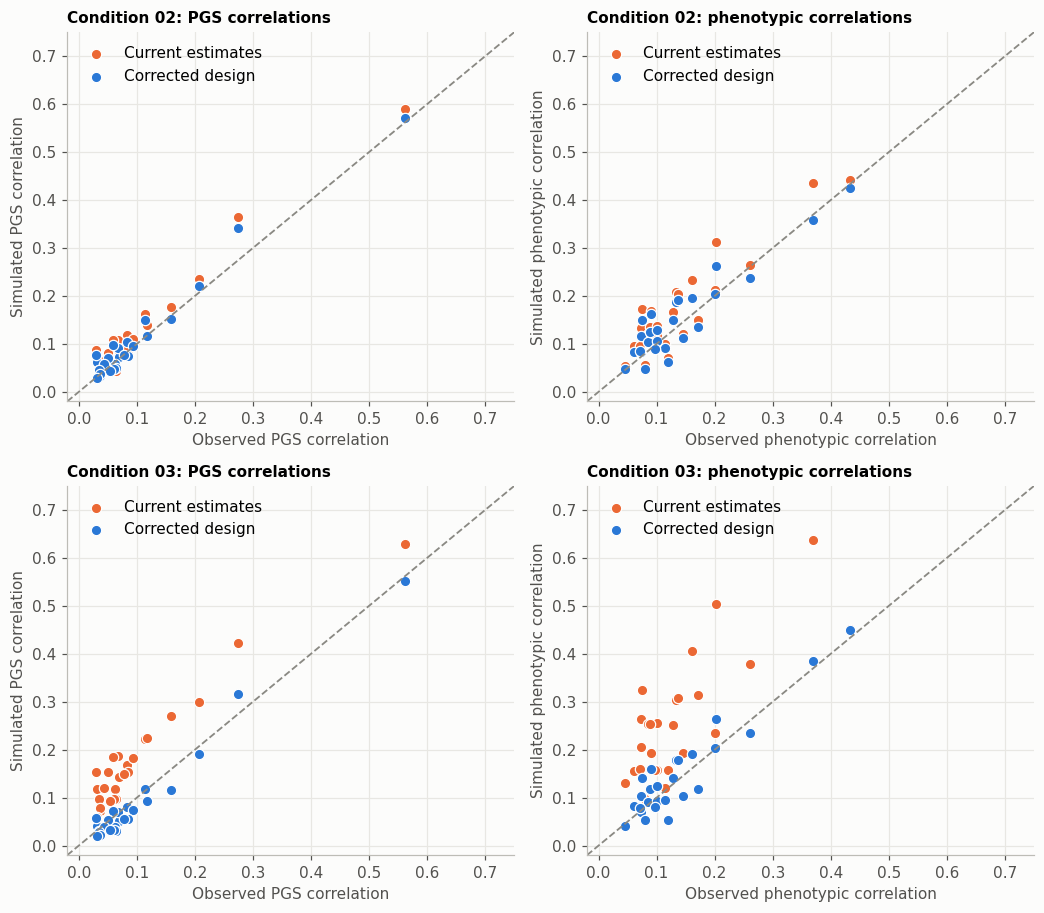

In [10]:
pairs = [("02", "02_current", "02_base"), ("03", "03_current", "03_re")]
pgs = [f for f in F if "PGS" in f]; ph = [f for f in F if f.endswith("_Y1")]
means = v.groupby("design")[F].mean()
fig, axes = plt.subplots(2, 2, figsize=(9.6, 8.4))
for row, (name, before, after) in enumerate(pairs):
    for col, (cols, what) in enumerate([(pgs, "PGS"), (ph, "Phenotypic")]):
        ax = axes[row, col]; lim = (-.02, 0.75)
        ax.plot(lim, lim, ls="--", color=GREY, lw=1.2)
        ax.scatter(OBS[cols], means.loc[before, cols], s=46, color=ORANGE, edgecolor="white", linewidth=.8, label="Current estimates")
        ax.scatter(OBS[cols], means.loc[after, cols], s=46, color=BLUE, edgecolor="white", linewidth=.8, label="Corrected design")
        ax.set(xlim=lim, ylim=lim, xlabel=f"Observed {what if what == 'PGS' else what.lower()} correlation", ylabel=f"Simulated {what if what == 'PGS' else what.lower()} correlation")
        ax.set_title(f"Condition {name}: {what if what == 'PGS' else what.lower()} correlations", fontsize=10); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

- **The biggest gain is in condition 03.** Its current estimates give a sibling phenotypic correlation of 0.64 and a misfit of 8.4. Correcting the scale alone halves that, and freeing `re` and `prop_h2_latent1` halves it again.
- **In condition 02 the current estimates are not far off, but they rely on a heritability of 0.51 to 0.63.** With the corrected scale the fit improves, with a founder heritability of 0.39.
- **Founder heritability in the family-environment designs is slightly above `vg1`** because the family term applies from generation 1, so it is absent from the founders.
- **Base variance is not current variance.** In the corrected 02 design the genetic variance grows from 0.39 to 0.66 under assortment, and heritability rises to 0.52 by generation 15. That rise is what gets the sibling correlation to 0.36.
- **Family environment gives the remaining gain.** Without it the sibling's-child and cousin phenotypic correlations stay too high (0.26 and 0.20 against 0.20 and 0.16), because everything that makes siblings similar is genetic. A term shared only by siblings breaks that link. The observed ratio of sibling to sibling's-child correlation (1.83) is matched by the 02 family-environment design (1.82), and not by the corrected 02 design without it (1.37).
- **Condition 03 ends up looking much like condition 02.** Once `re` is free the best `f11` is about 0.07 (0.00 with family environment), so EA vertical transmission is not supported. Its main remaining difference from 02 is `f22`, which is not identified.

## 7. What to change

### 7.1 Correct the genetic scale (conditions 02 and 03, and every other condition)

In `run_single_iteration` of each `DataGeneratingNN_Combined_*_wider.py`, and in each `run_predicted_condition_rc_*.py`, build the variants first and pass them through `cv_info` in place of `n_CV`, `rg_effects`, `maf_min` and `maf_max`. `sim_driver.py` runs this path, so it has been tested through the engine.

```python
cv_info = AssortativeMatingSimulation.prepare_CV_random_selection(
    N_CV, params['rg'], MAF_MIN, MAF_MAX,
    1 - params['prop_h2_latent1'], 1 - params['prop_h2_latent2'])
cv_info['alpha1'] *= np.sqrt(params['vg1'])
cv_info['alpha2'] *= np.sqrt(params['vg2'])

sim = AssortativeMatingSimulation(
    cv_info=cv_info,                    # replaces n_CV, rg_effects, maf_min, maf_max
    num_generations=N_GENERATIONS,
    # ... the remaining arguments are unchanged
)
```

`IslandMigrationSimulation` forwards its keyword arguments to this class, so `cv_info` can be passed the same way for condition 04. An existing `vg1` or `vg2` value converts to a founder heritability of `1 / (2 - vg)`.

The alternative is to fix this inside the engine so that `a_mat` and `d_mat` scale the effects, as its README describes. That changes behaviour everywhere the submodule is used, so it should be a deliberate change.

### 7.2 Which parameters to free or fix, and over what range

The ranges below concentrate simulations where the observed pattern can occur. Under the emulators, the share of draws reaching the observed spouse and sibling correlations together rises several-fold (table below).

**Condition 02: AE with assortment on a latent trait**

| Parameter | Now | Proposed | Why |
|---|---|---|---|
| `vg1` | free, 0.05-0.95 (production scale) | free, 0.1-0.7 (true scale) | Fit is best at about 0.27-0.50 |
| `prop_h2_latent1` | free, 0.05-0.95 | free, 0.4-0.95 | Below about 0.4 the fit is worse |
| `re` | free, 0-0.95 | free, 0.1-0.95 | Best near 0.5; poor at 0 |
| `am22` | free, 0.05-0.95 | free, 0.5-0.95 | Best near 0.84; poor below 0.6 |
| `rg` | free, 0-0.99 | free, 0.3-0.99 | Poor below about 0.35 |
| `vg2` | 0.5 | 0.5, now really 0.5 | Freeing it did not help |

**Condition 03: AE, vertical transmission, assortment on a latent trait**

| Parameter | Now | Proposed | Why |
|---|---|---|---|
| `vg1` | free, 0.05-0.95 (production scale) | free, 0.25-0.45 (true scale), or fixed at 0.35 | The data do not determine it |
| `re` | fixed, 0.1 | **free, 0.3-0.95** | 0.1 cannot produce the spouse correlation |
| `prop_h2_latent1` | fixed, 0.7 | **free, 0.4-0.95** | Same treatment as condition 02 |
| `f11` | free, 0-0.4 | free, 0-0.2 | Fit worsens as `f11` rises |
| `f22` | free, 0-0.4 | free, 0-0.25, or fixed at 0 | Not identified; large values inflate trait 2's variance |
| `am22` | free, 0.05-0.95 | free, 0.5-0.95 | Poor below about 0.55 |
| `rg` | free, 0-0.99 | free, 0.3-0.99 | Poor below about 0.3 |
| `vg2` | 0.5 | 0.5, now really 0.5 | Freeing it did not help reliably |
| `s11`, `s12`, `s21`, `s22` | 0.5 | Remove | The engine never applies them |

In [11]:
c = pd.read_csv(RESULTS / "exp4_joint_coverage.csv")
c["share"] = (c["share"] * 100).round(3)
c.columns = ["Design", "Ranges", "% of draws near the observed pattern", "Expected rows out of 20,000"]
display(c.set_index(["Design", "Ranges"]))

% of draws near the observed pattern  Expected rows out of 20,000
Design       Ranges                                                                     
02_freevg    full                                     0.052                           10
             proposed                                 0.429                           86
03_re_freevg full                                     0.012                            2
             proposed                                 0.414                           83

"Near the observed pattern" means the emulated spouse phenotypic, spouse PGS and sibling phenotypic correlations are all within the windows of section 2. These are emulator estimates, so read them as a rough guide. The windows are strict; the proposed ranges matter because they put about 8 times (02) and 33 times (03) more training rows in that region.

### 7.3 Decision for you: a family environment term

The family-environment designs fit best (1.61 for 02 and 1.54 for 03) and correct the sibling's-child and cousin correlations. They add two free parameters (`c1`, `c2`), and condition 02 would no longer be a pure AE model. The `s = 0.5` setting suggests condition 03 was meant to have shared family environment already, so 03 is the natural place to add it. `FamilyEnvSimulation` in `sim_driver.py` is a tested subclass that does this through the engine's `_post_offspring_hook` with no engine change.

### 7.4 Steps after the changes

1. Apply 7.1 and 7.2 to `DataGeneratingNN_Combined_02AElatentAM_wider.py` and `DataGeneratingNN_Combined_03EnvLatentAM_wider.py`, using new output folders so the current training data stay intact.
2. Regenerate the 20,000 rows per condition on CURC, and combine with `submit_combine_nn_wider.sh`.
3. Refit with `run_npe_pipeline.py`, and update `check_predicted_conditions.py` for the new parameters.
4. Apply 7.1 and the new estimates to the two `run_predicted_condition_rc_*` scripts, then submit. These must use the same scale, or the estimates will not mean the same thing in the two steps.
5. Check the new fits before trusting them: most of the unrestricted posterior should fall inside the range (0% and 7% now), no parameter should sit at a bound, and the simulated correlations should approach the corrected designs in section 6.

If you want predicted conditions before a new NPE run, these verified parameter sets can be used directly, on the true scale (values from `results/exp4_best_params.csv`):

In [12]:
b = pd.read_csv(RESULTS / "exp4_best_params.csv").set_index("design")
pars = ["vg1", "prop_h2_latent1", "re", "am22", "rg", "f11", "f22", "vg2", "c1", "c2"]
t = b.loc[["02_base", "02_c", "03_re", "03_re_c"], pars].copy()
for design in t.index:
    for k, val in DESIGNS[design]["fixed"].items():
        t.loc[design, k] = val
t = t.round(3)
t.loc[["02_base", "02_c"], ["f11", "f22"]] = 0
t = t.fillna(0)
t.index = ["02: true scale", "02: with family environment", "03: true scale, re free", "03: with family environment"]
display(t.T)

,02: true scale,02: with family environment,"03: true scale, re free",03: with family environment
vg1,0.391,0.385,0.391,0.301
prop_h2_latent1,0.725,0.636,0.697,0.687
re,0.551,0.791,0.950,0.948
am22,0.858,0.731,0.680,0.715
rg,0.689,0.651,0.656,0.652
f11,0.000,0.000,0.069,0.000
f22,0.000,0.000,0.135,0.092
vg2,0.500,0.495,0.500,0.500
c1,0.000,0.106,0.000,0.123
c2,0.000,0.311,0.000,0.348


## 8. Limits of this analysis

- **Population size.** Screening used N = 6,000 and verification N = 12,000, each with 500 variants, against N = 40,000 and 1,000 variants in production. Correlations involving PGS vary more at this size. The misfit values for individual replicates have an SD of 0.2 to 0.9.
- **Emulators.** They have a cross-validated error of about 0.02 to 0.03 in correlation units. For two designs the verified misfit was clearly worse than the emulator predicted (02 with `vg1` free: 1.87 predicted, 2.65 verified; 03 with `vg1` free: 1.68 predicted, 2.85 verified). So the rankings among designs with verified misfit between about 1.9 and 2.3 are not reliable, and the "best parameters" are good settings, not estimates.
- **Search limits.** The best `re` in the corrected 03 designs is 0.95, the top of the range searched. A correlation that high between the two environments may be standing in for something the model lacks.
- **No design fits to within sampling error.** Misfit would be about 1 for a model that fits within sampling error. The best here are 1.5 to 1.6, so some of the pattern remains unexplained.
- **No NPE on corrected-scale data.** Whether the fits become stable after the change is expected but untested. The checks in 7.4 are there to confirm it.
- **Reproducing this notebook.** Results are in `results/`, which is git-ignored; the saved cell outputs keep the numbers. To regenerate them, run in this folder:

```bash
python exp1_engine_scale.py
python run_npe_variants.py
python run_design.py --tag screen --n 140 --N 6000 --n_cv 500 --workers 9
python analyze_designs.py --tag screen
python verify_designs.py --workers 8 --reps 6
python profile_designs.py
python joint_coverage.py
```